# SPC for quality improvement: a real NHS A&E example

Statistical process control (SPC) exists to answer one question: *is this
change in the data worth investigating, or just noise?* That's central to
quality improvement generally. `spc` follows the guidelines set out by
the NHS's ["Making Data
Count"](https://www.england.nhs.uk/publication/making-data-count/)
programme, because those guidelines get something right: they favour
methods that are simple to compute, explain, and act on, over ones that
only make sense to a professional statistician or data scientist.

This notebook is a short, real-data walkthrough of what `spc` gives you
for that: a genuine shift getting flagged, `suggest_rebase()` finding
where to split a baseline, a second chart family fitted against a
properly out-of-sample baseline instead of a flat mean, a T chart for rare
events, and the plain data contract underneath it all. It complements the reference tour of
nine of the eleven chart kinds in `scripts/demo_ae_admissions.py` — see the main
[README](../README.md) for the full picture.

**Data**: real NHS England A&E attendance figures for one major A&E
department (trust `RJZ`, type "1"), April 2016 -- March 2019, from the
pinned [NHSRdatasets](../tests/golden/nhsrdatasets/PROVENANCE.md)
snapshot — not synthetic, apart from section 4, which uses simulated rare
events and says so. The shift below is a real, if modest, feature of the
actual data.

**Caveat**: section 1's `xmr` chart uses a flat-mean baseline (`spc`'s
default) rather than a seasonally-modelled one. A&E admissions and
breach rates have a real winter/summer cycle a flat mean can't
represent — that's a limitation of *this example*, not of `spc` itself:
the library accepts a caller-supplied baseline
(`BaseChartOptions.baseline`) for exactly this case; computing a proper
seasonal model is left to the caller. Section 3 below shows what
actually supplying one looks like, fitted honestly on a held-out split
of this same dataset.

In [1]:
import json

import pandas as pd
import plotly.graph_objects as go
import plotly.io as pio

import spc
from spc.core.models import BaseChartOptions, ExternalBaseline, LimitMode, ProportionChartOptions
from spc.render.plotly_renderer import POINT_COLOURS, POINT_TYPE_LABELS

pio.renderers.default = "svg"  # static images -- GitHub's notebook viewer renders neither the Plotly JSON mimetype nor <script>-based HTML outputs (it sanitises scripts out), so nothing interactive survives being viewed there. Install the notebook extra and Chrome for static output (see README); use plotly_mimetype for interactive Jupyter output.

ae = pd.read_parquet("../tests/golden/nhsrdatasets/ae_attendances.parquet")
rjz = ae[(ae["org_code"] == "RJZ") & (ae["type"] == "1")].sort_values("period").reset_index(drop=True)
rjz[["period", "attendances", "breaches", "admissions"]]

,period,attendances,breaches,admissions
0,2016-04-01,16688.0,3608.0,4504.0
1,2016-05-01,17656.0,3515.0,4531.0
2,2016-06-01,17247.0,3730.0,4577.0
3,2016-07-01,17404.0,3805.0,4486.0
4,2016-08-01,16316.0,2572.0,4394.0
5,2016-09-01,16771.0,4042.0,4482.0
6,2016-10-01,16936.0,4252.0,4366.0
7,2016-11-01,16842.0,4568.0,4329.0
8,2016-12-01,17326.0,5682.0,4487.0
9,2017-01-01,16752.0,4887.0,4419.0


## 1. Detecting a genuine shift

Monthly admissions is a continuous count — a natural fit for an `xmr`
chart, the library's default chart kind. `limit_mode="segment"` (the
default) treats the whole series as one segment and computes one set of
limits from it.

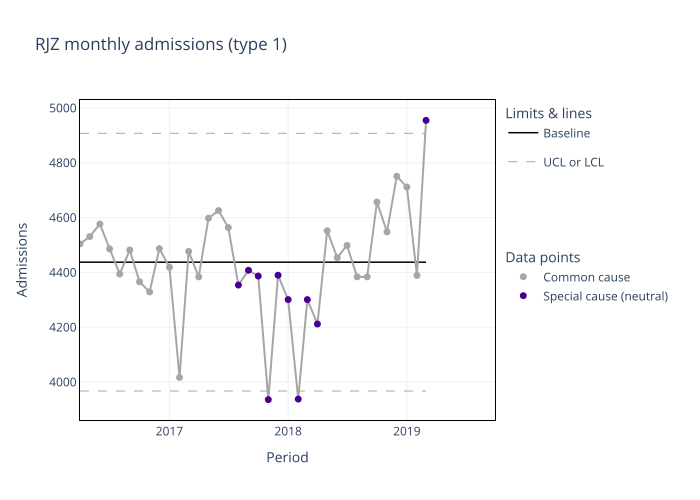

In [2]:
xmr_options = BaseChartOptions(value_field="admissions", date_field="period", improvement_direction="neutral")
xmr_result = spc.chart(rjz, kind="xmr", options=xmr_options)
spc.render.plotly(xmr_result, title="RJZ monthly admissions (type 1)")

In [3]:
seg_flagged = [p for p in xmr_result.points if p.special_cause_rule]
print(f"{len(seg_flagged)} of {len(xmr_result.points)} points flagged:")
for p in seg_flagged:
    print(f"  {p.x}  {p.y:>7,.0f}  {p.special_cause_rule}")

10 of 36 points flagged:
  2017-08-01    4,354  seven_point_shift
  2017-09-01    4,408  seven_point_shift
  2017-10-01    4,387  seven_point_shift
  2017-11-01    3,936  outside_limits
  2017-12-01    4,390  seven_point_shift
  2018-01-01    4,301  seven_point_shift
  2018-02-01    3,938  outside_limits
  2018-03-01    4,301  seven_point_shift
  2018-04-01    4,212  seven_point_shift
  2019-03-01    4,955  outside_limits


A run of `seven_point_shift` points clusters from August 2017 through
April 2018 — nine months where admissions ran consistently below the
series baseline, not a one-off blip. That's exactly the kind of signal SPC
is for: a sustained, real shift in an operational metric, distinguishable
from a single unusually quiet month.

## 2. `suggest_rebase()`: finding where to split the baseline

Rather than picking `fix_after_n_points` by eye, `suggest_rebase()` scans
a chart's own special-cause flags for candidate points to start a new
baseline from — useful once you suspect a shift has happened and want to
start monitoring against a fresh, post-shift normal.

In [4]:
for s in spc.suggest_rebase(xmr_result):
    print(f"{s.candidate_date}  {s.rule:<16} {s.points_since} pts since   confidence={s.confidence}")

2017-08-01  seven_point_shift 9 pts since   confidence=low


## 3. A second chart family, fitted against a properly out-of-sample baseline

4-hour breach rate (`breaches / attendances`) is a true proportion with a
varying denominator month to month — a `p` chart, not `xmr`. It's also a
strongly seasonal metric (NHS "winter pressure"), which is exactly where
`spc`'s flat-mean default (see the caveat at the top of this notebook)
falls down.

To fix that honestly, not just illustrate the problem: RJZ's three years
of data are split into a 24-month fitting period (April 2016 -- March
2018) and a 12-month evaluation period (April 2018 -- March 2019). A
simple seasonal baseline — the mean breach rate for each calendar month,
computed only from the fitting period — is fit once, then used to
predict the evaluation period's 12 expected values, matched by calendar
month.

Two things are deliberate:
- The fitting period's *real data* is still shown below, as a plain dark
  blue line with no markers — but it's never itself classified against a
  baseline or control limits, and gets no Baseline line, no UCL/LCL, no
  point colour. Doing that would be circular: it would only show the
  model fitting itself, not whether it generalises.
- The SPC analysis — the green Baseline line (this chart's seasonal
  centre line, not a flat mean), the green UCL/LCL band, the
  special-cause flagging — is computed only for the 12-month evaluation
  period, because that's the only period where an actual out-of-sample
  baseline prediction exists to judge points against.

fit on:    2016-04-01 -- 2018-03-01 (24 months)
evaluate:  2018-04-01 -- 2019-03-01 (12 months)


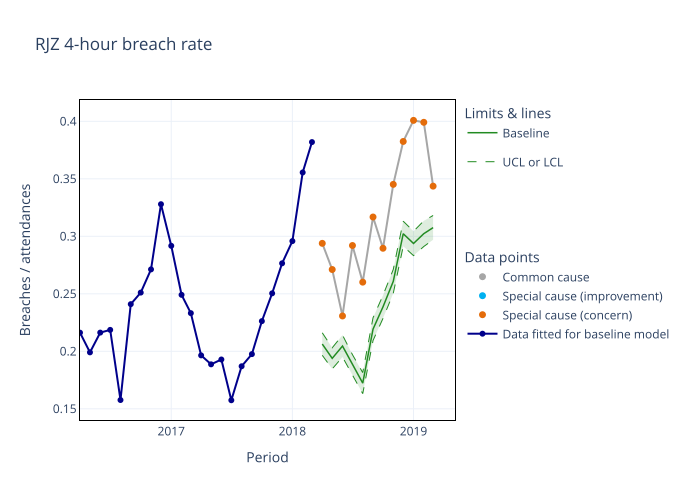

In [5]:
train = rjz.iloc[:24].copy()
test = rjz.iloc[24:].copy()
print(f"fit on:    {train['period'].min()} -- {train['period'].max()} ({len(train)} months)")
print(f"evaluate:  {test['period'].min()} -- {test['period'].max()} ({len(test)} months)")

train["breach_rate"] = train["breaches"] / train["attendances"]
seasonal_mean_by_month = train.groupby(train["period"].apply(lambda d: d.month))["breach_rate"].mean()

seasonal_baseline = [
    ExternalBaseline(
        x=row.period,
        expected_value=seasonal_mean_by_month[row.period.month],
        source="seasonal (month-of-year) mean, fitted on Apr 2016 - Mar 2018",
    )
    for row in test.itertuples()
]

p_options = ProportionChartOptions(
    value_field="breaches", date_field="period", denominator_field="attendances", improvement_direction="decrease",
    baseline=seasonal_baseline,
)
p_result = spc.chart(test, kind="p", options=p_options)
fig = spc.render.plotly(
    p_result, title="RJZ 4-hour breach rate", shade_limits=True,
    baseline_colour="#228b22", limit_colour="#228b22",
)

# The renderer only adds a "Data points" legend entry for point_types
# actually present in the analysed data -- every evaluation-year point
# happens to be special_cause_concern (see below), so common_cause and
# special_cause_improvement are inserted here too, purely so the legend
# still explains the full colour key even for colours that don't occur.
# Inserted before the "Special cause (concern)" entry the renderer
# already added, so the legend keeps its usual common/improvement/concern
# order rather than reading oddly out of sequence.
fig.add_traces([
    go.Scatter(
        x=[None], y=[None], mode="markers",
        marker={"color": POINT_COLOURS[point_type], "size": 7},
        name=POINT_TYPE_LABELS[point_type], legend="legend2",
    )
    for point_type in ("common_cause", "special_cause_improvement")
])
# fig.data only accepts a *permutation* of its own already-registered
# traces, not new ones assigned in place -- so the two traces above are
# added (appending at the end) first, then moved into position by
# reordering the existing tuple, not by splicing new objects into it.
traces = list(fig.data)
new_traces, traces = traces[-2:], traces[:-2]
concern_idx = next(i for i, t in enumerate(traces) if t.name == "Special cause (concern)")
traces[concern_idx:concern_idx] = new_traces
fig.data = tuple(traces)

# The fitting period's real data, added directly to the figure -- same
# line style as the evaluation period's own connecting line, but dark
# blue rather than grey so it doesn't read as another "common cause"
# classification -- it isn't one, it was never analysed at all (it gets
# no Baseline line, no UCL/LCL, no point classification -- see the
# markdown above for why). Markers are plain circles in the same colour,
# not point_type-coloured, for the same reason.
fig.add_trace(
    go.Scatter(
        x=train["period"], y=train["breach_rate"], mode="lines+markers",
        line={"color": "#00008b", "width": 2}, marker={"color": "#00008b", "size": 6},
        name="Data fitted for baseline model", legend="legend2",
    )
)
fig.update_xaxes(range=[train["period"].min(), fig.layout.xaxis.range[1]])
fig

In [6]:
flagged = [p for p in p_result.points if p.special_cause_rule]
print(f"{len(flagged)} of {len(p_result.points)} evaluation-year points flagged:")
for p in p_result.points:
    print(f"  {p.x}  actual {p.y:.3f}  vs. expected {p.mean:.3f}  -- {p.point_type}")

12 of 12 evaluation-year points flagged:
  2018-04-01  actual 0.294  vs. expected 0.206  -- special_cause_concern
  2018-05-01  actual 0.271  vs. expected 0.194  -- special_cause_concern
  2018-06-01  actual 0.231  vs. expected 0.205  -- special_cause_concern
  2018-07-01  actual 0.292  vs. expected 0.188  -- special_cause_concern
  2018-08-01  actual 0.260  vs. expected 0.172  -- special_cause_concern
  2018-09-01  actual 0.317  vs. expected 0.219  -- special_cause_concern
  2018-10-01  actual 0.290  vs. expected 0.239  -- special_cause_concern
  2018-11-01  actual 0.345  vs. expected 0.261  -- special_cause_concern
  2018-12-01  actual 0.382  vs. expected 0.302  -- special_cause_concern
  2019-01-01  actual 0.401  vs. expected 0.294  -- special_cause_concern
  2019-02-01  actual 0.399  vs. expected 0.302  -- special_cause_concern
  2019-03-01  actual 0.344  vs. expected 0.308  -- special_cause_concern


Every one of the 12 evaluation months reads as `special_cause_concern`.
Once the seasonal pattern is properly subtracted out, using a baseline
model that was never allowed to see this year's data, there's no seasonal
noise left to hide behind. What's left is a real, undiluted signal:
RJZ's 4-hour breach rate was genuinely worse throughout April 2018 --
March 2019 than the equivalent calendar months of the two years used to
fit the baseline.

This is, of course, only intended to be a simple demo of how the library
works, not a research-quality report on a real dataset.

## 4. Rare events: a `t` chart (simulated data)

When the event you care about is rare, counting events per month gives mostly
zeros and says little. Plot the time *between* events instead: a `t` chart.
The input is just a column of event timestamps — `value_field` — and `spc`
works out the gaps itself. (Gaps are skewed, so `spc` transforms them, as T
charts do, before applying the usual limits, and reports everything back in
days.) `date_field` is required by the shared options but not read for `t`, so
it is simply given the same column.

The pinned NHS data has no genuinely rare events, so this section is
**simulated**: a seeded series of 24 falls with harm on one ward. The first 14
gaps average about a month; the last 9 average about a week. It is
illustrative, not real data.

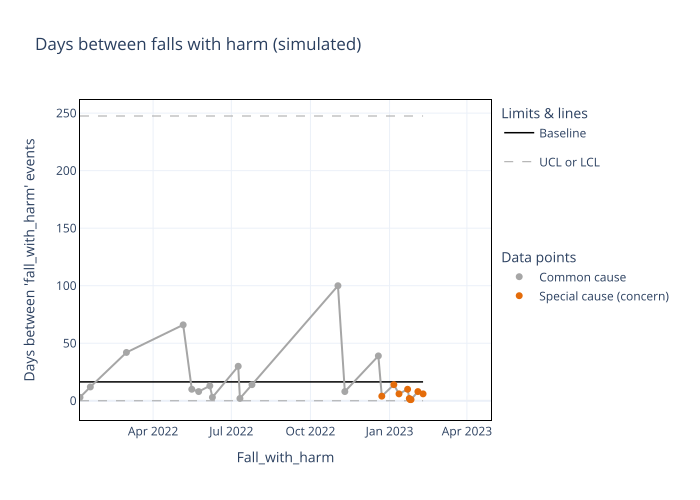

In [7]:
import numpy as np

rng = np.random.default_rng(3)
gaps_in_days = np.r_[
    np.maximum(rng.exponential(30, 14).round(), 1),  # the stable period
    np.maximum(rng.exponential(7, 9).round(), 1),  # falls start happening much more often
]
falls = pd.DataFrame(
    {"fall_with_harm": pd.Timestamp("2022-01-03") + pd.to_timedelta(np.r_[0, np.cumsum(gaps_in_days)], unit="D")}
)

t_options = BaseChartOptions(
    value_field="fall_with_harm",
    date_field="fall_with_harm",
    limit_mode=LimitMode.FIXED_N,  # limits from the first 14 gaps only (known-stable history)
    fix_after_n_points=14,
    improvement_direction="increase",  # a longer gap between falls is better
)
t_result = spc.chart(falls, kind="t", options=t_options)
spc.render.plotly(t_result, title="Days between falls with harm (simulated)")

In [8]:
t_flagged = [p for p in t_result.points if p.special_cause_rule]
print(f"{len(t_flagged)} of {len(t_result.points)} gaps flagged, first on {t_flagged[0].x}:")
for p in t_flagged:
    print(f"  {p.x}  gap of {p.y:>3.0f} d  {p.special_cause_rule}  ({p.point_type})")

9 of 23 gaps flagged, first on 2022-12-23:
  2022-12-23  gap of   4 d  seven_point_shift  (special_cause_concern)
  2023-01-06  gap of  14 d  seven_point_shift  (special_cause_concern)
  2023-01-12  gap of   6 d  seven_point_shift  (special_cause_concern)
  2023-01-22  gap of  10 d  seven_point_shift  (special_cause_concern)
  2023-01-24  gap of   2 d  seven_point_shift  (special_cause_concern)
  2023-01-25  gap of   1 d  seven_point_shift  (special_cause_concern)
  2023-01-26  gap of   1 d  seven_point_shift  (special_cause_concern)
  2023-02-03  gap of   8 d  seven_point_shift  (special_cause_concern)
  2023-02-09  gap of   6 d  seven_point_shift  (special_cause_concern)


The 14 baseline gaps show no signal. Every one of the 9 gaps after them is
flagged as `special_cause_concern` by `seven_point_shift`: falls are arriving
much faster than the baseline predicts. No single gap breaches a control limit,
so a threshold alert on the gap length would have stayed quiet — the change
shows up as a sustained shift, which is what SPC is for.

## 5. The underlying contract

Everything above is UI-independent: `spc.chart()` returns a plain
pydantic `ChartResult`. The Plotly figures are one optional way to look
at it (demo-grade, per the README) — the JSON is what you'd actually
persist or serve from an API, or hand to your own rendering layer.

In [9]:
payload = json.loads(p_result.model_dump_json())
print("top-level keys:", list(payload.keys()))
print(json.dumps(payload["points"][0], indent=2))

top-level keys: ['schema_version', 'kind', 'options', 'points', 'segments', 'assurance_type', 'suggested_kind', 'autocorrelation_uncorrected_rules', 'generated_at']
{
  "x": "2018-04-01",
  "y": 0.29388867263526663,
  "facet": null,
  "facet_parts": null,
  "segment_id": 0,
  "mean": 0.20632715596130952,
  "ucl": 0.21610543741813348,
  "lcl": 0.19654887450448555,
  "outside_limits": true,
  "special_cause_rule": "outside_limits",
  "point_type": "special_cause_concern",
  "low_count_warning": false,
  "spec_breach": false
}
